In [1]:
# Cell 1 (binary): imports, paths, load fold JSONs and results_per_fold
import os, glob, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, precision_recall_fscore_support
import joblib
import warnings
warnings.filterwarnings("ignore")

# ---------------- CONFIG (edit paths if needed) ----------------
OUT_DIR = Path("C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/loso_results/label_binary/2025-12-28_14-37-16")
CSV_PATH = Path("C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features/features_final_prepared.csv")
SAVE_DIR = OUT_DIR / "analysis"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# constants
RANDOM_STATE = 42
N_BOOT = 1000
ALPHA = 0.05

# ---------------- Load fold JSONs and results per fold ----------------
fold_files = sorted(glob.glob(str(OUT_DIR / "fold_*_summary.json")))
folds = [json.load(open(f)) for f in fold_files]
print(f"Loaded {len(folds)} fold JSON files for binary label run")

# load results_per_fold if exists, else build from folds
results_csv = SAVE_DIR / "results_per_fold.csv"
if results_csv.exists():
    df_folds = pd.read_csv(results_csv)
else:
    rows = []
    for j in folds:
        fold = int(j['test_subject'])
        for mname, m in j.get('models', {}).items():
            rows.append({
                'fold': fold,
                'model': mname,
                'n_train_rows': j['n_train_rows'],
                'n_test_rows': j['n_test_rows'],
                'balacc_epoch': m.get('test_balanced_accuracy_epoch', np.nan),
                'acc_epoch': m.get('test_accuracy_epoch', np.nan),
                'f1_epoch': m.get('test_f1_epoch', np.nan),   # should be binary F1 from your pipeline
                'auc_epoch': m.get('test_auc_epoch', np.nan), # binary AUC if available
                'balacc_task': m.get('test_balanced_accuracy_task', np.nan),
                'acc_task': m.get('test_accuracy_task', np.nan),
                'f1_task': m.get('test_f1_task', np.nan),
                'auc_task': m.get('test_auc_task', np.nan),
                'n_tasks_test': m.get('n_tasks_test', np.nan),
            })
    df_folds = pd.DataFrame(rows)
    df_folds = df_folds.sort_values(by='fold', ascending=True)
    df_folds.to_csv(results_csv, index=False)

# quick checks
print("models found:", df_folds['model'].unique())
print("folds count:", df_folds['fold'].nunique())

Loaded 29 fold JSON files for binary label run
models found: ['XGB' 'TangentLR' 'RF' 'MDM']
folds count: 29


In [2]:
df_folds

,fold,model,n_train_rows,n_test_rows,balacc_epoch,acc_epoch,f1_epoch,auc_epoch,balacc_task,acc_task,f1_task,auc_task,n_tasks_test
40,1,XGB,21038,793,0.555839,0.556116,0.636364,0.653512,0.500000,0.500000,0.666667,0.722222,12
43,1,TangentLR,21038,793,0.624195,0.624212,0.629353,0.678078,0.750000,0.750000,0.727273,0.805556,12
41,1,RF,21038,793,0.522791,0.523329,0.666078,0.630111,0.500000,0.500000,0.666667,0.638889,12
42,1,MDM,21038,793,0.500000,0.500631,0.667227,NaN,0.500000,0.500000,0.666667,NaN,12
84,2,XGB,21059,772,0.693141,0.693005,0.707768,0.775301,0.750000,0.750000,0.769231,0.916667,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,28,TangentLR,21083,748,0.504819,0.508021,0.622951,0.577106,0.500000,0.500000,0.625000,0.583333,12
80,29,XGB,21094,737,0.569591,0.569878,0.588846,0.649441,0.583333,0.583333,0.615385,0.722222,12
81,29,RF,21094,737,0.598427,0.598372,0.596730,0.665695,0.500000,0.500000,0.500000,0.722222,12
83,29,TangentLR,21094,737,0.633799,0.633650,0.627072,0.661077,0.750000,0.750000,0.727273,0.694444,12


In [3]:
# Cell 2 (binary): Table 1 (mean ± 95% CI)
def bootstrap_ci_mean(x, n_boot=N_BOOT, seed=RANDOM_STATE):
    x = np.array(x.dropna()) if isinstance(x, pd.Series) else np.array(x)
    rng = np.random.RandomState(seed)
    boots = np.empty(n_boot)
    n = len(x)
    if n == 0:
        return np.nan, np.nan, np.nan
    for i in range(n_boot):
        sample = rng.choice(x, size=n, replace=True)
        boots[i] = sample.mean()
    return x.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

models = sorted(df_folds['model'].unique())
rows = []
for m in models:
    g = df_folds[df_folds['model']==m]
    mean, low, high = bootstrap_ci_mean(g['balacc_epoch'])
    rows.append({
        'model': m,
        'mean_balacc_epoch': mean,
        'balacc_95ci_low': low,
        'balacc_95ci_high': high,
        'mean_f1_epoch': g['f1_epoch'].mean(),
        'std_f1_epoch': g['f1_epoch'].std(),
        'mean_acc_epoch': g['acc_epoch'].mean(),
        'std_acc_epoch': g['acc_epoch'].std(),
        'mean_auc_epoch': g['auc_epoch'].mean(),   # binary AUC average
        'n_folds': int(g['fold'].nunique())
    })
table1 = pd.DataFrame(rows).sort_values('mean_balacc_epoch', ascending=False).reset_index(drop=True)
table1.to_csv(SAVE_DIR / "table1_model_performance_binary_CI_bootstrap.csv", index=False)
table1

,model,mean_balacc_epoch,balacc_95ci_low,balacc_95ci_high,mean_f1_epoch,std_f1_epoch,mean_acc_epoch,std_acc_epoch,mean_auc_epoch,n_folds
0,XGB,0.648449,0.614608,0.689976,0.625895,0.128522,0.648326,0.107108,0.717587,29
1,RF,0.625426,0.601839,0.652453,0.566712,0.158359,0.624890,0.072339,0.712721,29
2,TangentLR,0.619804,0.593765,0.646259,0.596391,0.119051,0.619462,0.072324,0.683818,29
3,MDM,0.570461,0.547905,0.595210,0.525073,0.191796,0.570355,0.065159,NaN,29


In [4]:
# Cell 3: Friedman omnibus and pairwise Wilcoxon with FDR and Cohen's d (paired)
from scipy.stats import friedmanchisquare, wilcoxon

# pivot to shape (fold x model) for primary metric
pivot = df_folds.pivot(index='fold', columns='model', values='balacc_epoch').dropna()
models = pivot.columns.tolist()

# Friedman omnibus
friedman_stat, friedman_p = friedmanchisquare(*(pivot[m].values for m in models))
print("Friedman:", friedman_stat, friedman_p)

# Pairwise Wilcoxon and effect sizes (Cohen's d for paired)
pairs = []
pvals = []
dvals = []
for i in range(len(models)):
    for j in range(i+1, len(models)):
        a = pivot[models[i]].values
        b = pivot[models[j]].values
        try:
            stat, p = wilcoxon(a, b)
        except Exception as e:
            # if wilcoxon fails (e.g., zero differences), fallback to t-test
            tstat, p = stats.ttest_rel(a, b, nan_policy='omit')
            stat = tstat
        diff = a - b
        # paired Cohen's d:
        d = diff.mean() / (diff.std(ddof=1) if diff.std(ddof=1) > 0 else np.nan)
        pairs.append(f"{models[i]} vs {models[j]}")
        pvals.append(p)
        dvals.append(d)

# FDR correction
reject, pvals_fdr, _, _ = multipletests(pvals, alpha=ALPHA, method='fdr_bh')
comp_df = pd.DataFrame({'pair': pairs, 'p_uncorrected': pvals, 'p_fdr': pvals_fdr, 'reject_fdr': reject, 'cohens_d': dvals})
comp_df.to_csv(SAVE_DIR / "table2_pairwise_binary_Wilcoxon_comparisons.csv", index=False)
print("Friedman omnibus:", friedman_stat, friedman_p)
comp_df

Friedman: 19.80000000000001 0.00018673656040772704
Friedman omnibus: 19.80000000000001 0.00018673656040772704


,pair,p_uncorrected,p_fdr,reject_fdr,cohens_d
0,MDM vs RF,0.000174,0.000523,True,-0.837622
1,MDM vs TangentLR,0.003389,0.006779,True,-0.651333
2,MDM vs XGB,0.000016,0.000096,True,-0.894765
3,RF vs TangentLR,0.949070,0.949070,False,0.064146
4,RF vs XGB,0.357853,0.429424,False,-0.293707
5,TangentLR vs XGB,0.247025,0.370538,False,-0.312507


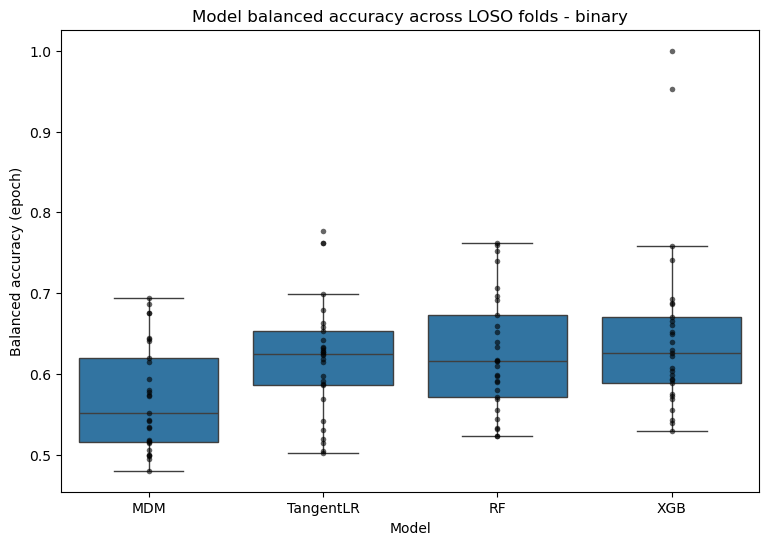

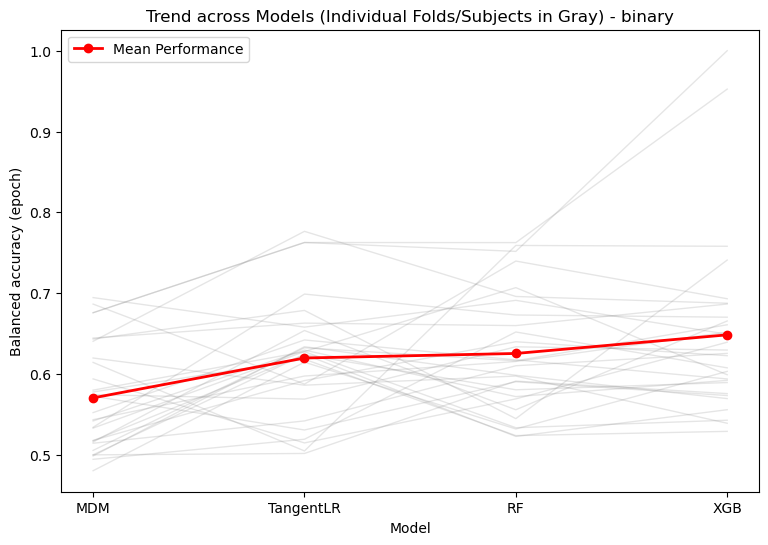

In [6]:
# # Cell 4: Figure 1 - boxplots + paired lines
model_order = ['MDM', 'TangentLR', 'RF', 'XGB']

# Pivot and then reorder the columns
pivot = df_folds.pivot(index='fold', columns='model', values='balacc_epoch').dropna()
pivot = pivot.reindex(columns=model_order)

plt.figure(figsize=(9,6))
sns.boxplot(x='model', y='balacc_epoch', data=df_folds, showfliers=False, order=model_order)
sns.stripplot(x='model', y='balacc_epoch', data=df_folds, color='k', size=4, jitter=False, alpha=0.6, order=model_order)
plt.ylabel("Balanced accuracy (epoch)")
plt.xlabel("Model")
plt.title("Model balanced accuracy across LOSO folds - binary")
plt.savefig(SAVE_DIR / "fig1_box_balacc_epoch_binary.png", dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(9,6))
for idx, row in pivot.iterrows():
    plt.plot(range(len(pivot.columns)), row.values, '-', color='gray', alpha=0.2, linewidth=1)
mean_vals = pivot.mean()
plt.plot(range(len(pivot.columns)), mean_vals, '-o', color='red', 
         linewidth=2, markersize=6, label='Mean Performance')
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.ylabel("Balanced accuracy (epoch)")
plt.xlabel("Model")
plt.legend()
plt.title("Trend across Models (Individual Folds/Subjects in Gray) - binary")
plt.savefig(SAVE_DIR / "fig1_per_subject_spaghetti_binary.png", dpi=150, bbox_inches='tight')
plt.show()

Best model binary: XGB


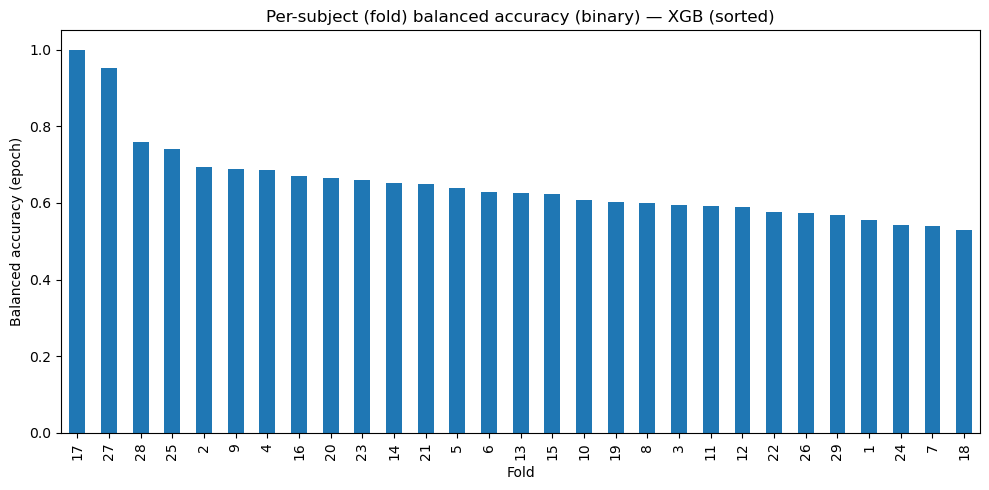

Best 5 subjects:
 |   fold |   balacc |
|-------:|---------:|
|     17 | 1        |
|     27 | 0.952505 |
|     28 | 0.758065 |
|     25 | 0.741    |
|      2 | 0.693141 |
Worst 5 subjects:
 |   fold |   balacc |
|-------:|---------:|
|     29 | 0.569591 |
|      1 | 0.555839 |
|     24 | 0.542839 |
|      7 | 0.539087 |
|     18 | 0.52904  |


In [7]:
# Cell 5: Per-subject bars for best model and table of best/worst subjects per model
# choose best model by mean in table1
best_model = table1.loc[0,'model']
print("Best model binary:", best_model)

pivot_best = df_folds[df_folds['model']==best_model].set_index('fold')['balacc_epoch']
sorted_pivot = pivot_best.sort_values(ascending=False)
plt.figure(figsize=(10,5))
sorted_pivot.plot(kind='bar')
plt.ylabel("Balanced accuracy (epoch)")
plt.xlabel("Fold")
plt.title(f"Per-subject (fold) balanced accuracy (binary) — {best_model} (sorted)")
plt.tight_layout()
plt.savefig(SAVE_DIR / f"fig2_per_subject_{best_model}_binary.png", dpi=200)
plt.show()

# best/worst 5
best5 = sorted_pivot.head(5).reset_index().rename(columns={'balacc_epoch':'balacc'})
worst5 = sorted_pivot.tail(5).reset_index().rename(columns={'balacc_epoch':'balacc'})
best5.to_csv(SAVE_DIR / f"{best_model}_best5_subjects_binary.csv", index=False)
worst5.to_csv(SAVE_DIR / f"{best_model}_worst5_subjects_binary.csv", index=False)
print("Best 5 subjects:\n", best5.to_markdown(index=False))
print("Worst 5 subjects:\n", worst5.to_markdown(index=False))

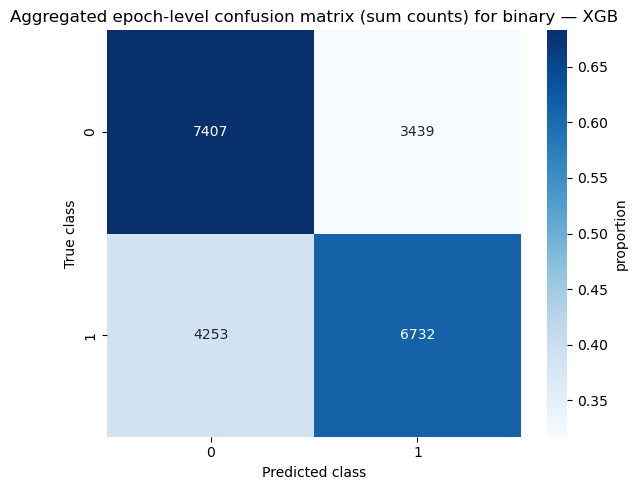

|   class |   precision |   recall |       f1 |
|--------:|------------:|---------:|---------:|
|       0 |    0.635249 | 0.682925 | 0.658224 |
|       1 |    0.661882 | 0.612836 | 0.636415 |


In [8]:
# Cell 6: Confusion matrices aggregated across folds for the chosen model
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

def aggregate_confusion(model_name, level='epoch'):
    # level: 'epoch' uses 'confusion_matrix_epoch' saved in JSONs; 'task' uses 'confusion_matrix_task'
    cm_sum = None
    for j in folds:
        m = j.get('models', {}).get(model_name, {})
        key = 'confusion_matrix_epoch' if level=='epoch' else 'confusion_matrix_task'
        cm = m.get(key, None)
        if cm is None:
            continue
        cm = np.array(cm)
        if cm_sum is None:
            cm_sum = cm.copy()
        else:
            cm_sum = cm_sum + cm
    return cm_sum

# epoch-level aggregated CM
cm_epoch = aggregate_confusion(best_model, level='epoch')
if cm_epoch is None:
    print("No epoch-level confusion matrices found for", best_model)
else:
    # normalize rows (true class)
    cm_norm = cm_epoch.astype(float) / cm_epoch.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6,5))
    sns.heatmap(cm_norm, annot=cm_epoch.astype(int), fmt='d', cmap='Blues', ax=ax, cbar_kws={'label':'proportion'})
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    ax.set_title(f'Aggregated epoch-level confusion matrix (sum counts) for binary — {best_model}')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / f"fig3_confusion_epoch_{best_model}_binary.png", dpi=200)
    plt.show()

# per-class precision/recall/f1 (from aggregated counts)
if cm_epoch is not None:
    tp = np.diag(cm_epoch).astype(float)
    recall = tp / cm_epoch.sum(axis=1)
    precision = tp / cm_epoch.sum(axis=0)
    f1 = 2 * (precision * recall) / (precision + recall)
    per_class = pd.DataFrame({'class': range(len(tp)), 'precision': precision, 'recall': recall, 'f1': f1})
    per_class.to_csv(SAVE_DIR / f"{best_model}_per_class_metrics_binary.csv", index=False)
    print(per_class.to_markdown(index=False))

Task-level rows: 1392


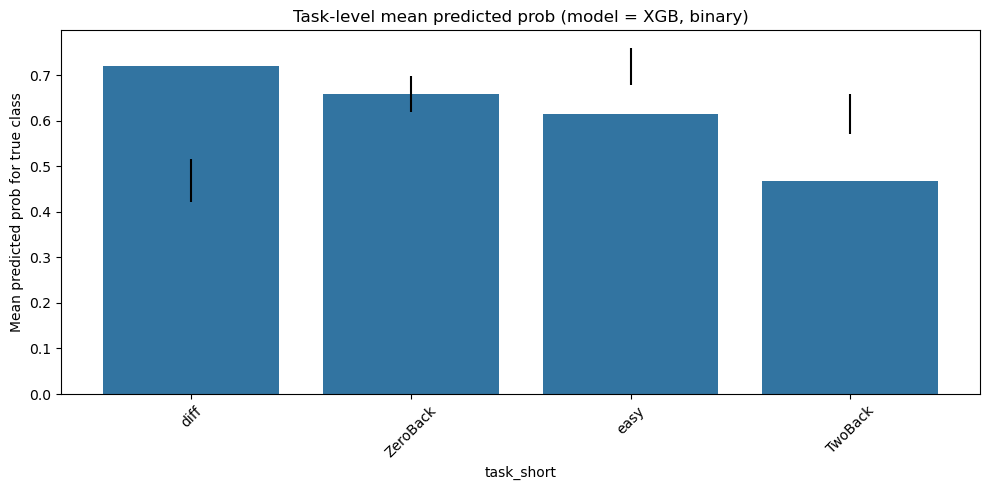

Trying method: lbfgs
Converged: True
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: prob_true
No. Observations: 348     Method:             REML     
No. Groups:       29      Scale:              0.0461   
Min. group size:  12      Log-Likelihood:     26.2218  
Max. group size:  12      Converged:          Yes      
Mean group size:  12.0                                 
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     0.636    0.020 31.792 0.000  0.597  0.676
true         -0.042    0.023 -1.835 0.067 -0.087  0.003
Group Var     0.004    0.010                           



C:\Users\User\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [11]:
# Cell 7: Build task-level dataframe across folds and test trend / mixed model
import statsmodels.formula.api as smf

task_rows = []
for j in folds:
    fold = int(j['test_subject'])
    for mname, m in j.get('models', {}).items():
        tlev = m.get('task_level_summary', {})
        for tid, info in (tlev.items() if isinstance(tlev, dict) else []):
            true = info.get('true', np.nan)
            pred = info.get('pred', np.nan)
            # ensure prob vector exists and fetch probability for true class
            prob = np.nan
            if info.get('prob') is not None and isinstance(info['prob'], (list, tuple)):
                try:
                    prob = float(info['prob'][int(true)])
                except Exception:
                    prob = np.nan
            task_rows.append({'fold': fold, 'model': mname, 'task_id': tid, 'true': int(true) if not np.isnan(true) else np.nan, 'pred': int(pred) if not np.isnan(pred) else np.nan, 'prob_true': prob})
task_df = pd.DataFrame(task_rows).dropna(subset=['prob_true'])
task_df.to_csv(SAVE_DIR / "task_level_summary_all_binary.csv", index=False)
print("Task-level rows:", len(task_df))

# plot mean prob_true by task id or by grouped task type if tidy names
# try to extract a short task label (e.g., OneBack / TwoBack / MATB_easy)
task_df['task_short'] = task_df['task_id'].apply(lambda x: str(x).split('_')[-2] if isinstance(x, str) and '_' in x else x)
agg = task_df[task_df['model']==best_model].groupby('task_short')['prob_true'].agg(['mean','count','std']).reset_index()
agg['ci_low'] = agg['mean'] - 1.96 * agg['std'] / np.sqrt(agg['count'])
agg['ci_high'] = agg['mean'] + 1.96 * agg['std'] / np.sqrt(agg['count'])
plt.figure(figsize=(10,5))
sns.barplot(x='task_short', y='mean', data=agg, order=agg.sort_values('mean', ascending=False)['task_short'])
plt.errorbar(x=np.arange(len(agg)), y=agg['mean'], yerr=[agg['mean']-agg['ci_low'], agg['ci_high']-agg['mean']], fmt='none', color='k')
plt.ylabel('Mean predicted prob for true class')
plt.title(f'Task-level mean predicted prob (model = {best_model}, binary)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(SAVE_DIR / f"fig4_task_probs_{best_model}_binary.png", dpi=200)
plt.show()

# Mixed-effects: prob_true ~ true (treat true as numeric ordered) with random intercept per fold
# try:
#     md = smf.mixedlm("prob_true ~ true", task_df[task_df['model']==best_model], groups=task_df[task_df['model']==best_model]["fold"])
#     mres = md.fit(reml=False)
#     print(mres.summary())
#     with open(SAVE_DIR / f"mixed_model_{best_model}_binary.txt", "w") as f:
#         f.write(mres.summary().as_text())
# except Exception as e:
#     print("Mixed model failed:", e)

    # Try different optimizers and REML
md = smf.mixedlm("prob_true ~ true", task_df[task_df['model']==best_model], groups=task_df[task_df['model']==best_model]["fold"])
# Try REML (more stable for variance components)
for method in ['lbfgs', 'bfgs', 'cg', 'powell', 'nm']:
    try:
        print("Trying method:", method)
        mres = md.fit(reml=True, method=method, maxiter=2000, full_output=True, tol=1e-6)
        print("Converged:", mres.mle_retvals.get('converged', True) if hasattr(mres, 'mle_retvals') else True)
        print(mres.summary())
        with open(SAVE_DIR / f"mixed_model_{best_model}_binary.txt", "w") as f:
            f.write(mres.summary().as_text())
        break
    except Exception as e:
        print("Method", method, "failed:", e)

In [14]:
import statsmodels.formula.api as smf

dfm0 = task_df[task_df['model'] == best_model].copy()

print("Rows:", len(dfm0))
print("Subjects:", dfm0['fold'].nunique())
print(dfm0.head())

import statsmodels.formula.api as smf

md = smf.mixedlm(
    "prob_true ~ true",
    dfm0,
    groups=dfm0["fold"]
)

mres = md.fit(
    reml=True,
    method="lbfgs",
    maxiter=2000,
    tol=1e-6
)

print(mres.summary())

ols = smf.ols("prob_true ~ true", data=dfm0).fit()

print("OLS AIC:", ols.aic)
print("Mixed AIC:", mres.aic)

ols_cluster = smf.ols(
    "prob_true ~ true",
    data=dfm0
).fit(
    cov_type="cluster",
    cov_kwds={"groups": dfm0["fold"]}
)

print(ols_cluster.summary())

Rows: 348
Subjects: 29
   fold model                                task_id  true  pred  prob_true  \
0    10   XGB  sub-10_ses-01_MATB_diff_clean-epo.fif     1     1   0.665039   
1    10   XGB  sub-10_ses-01_MATB_easy_clean-epo.fif     0     0   0.505370   
2    10   XGB    sub-10_ses-01_TwoBack_clean-epo.fif     1     1   0.566335   
3    10   XGB   sub-10_ses-01_ZeroBack_clean-epo.fif     0     1   0.205407   
4    10   XGB  sub-10_ses-02_MATB_diff_clean-epo.fif     1     1   0.829953   

  task_short  
0       diff  
1       easy  
2    TwoBack  
3   ZeroBack  
4       diff  


C:\Users\User\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: prob_true
No. Observations: 348     Method:             REML     
No. Groups:       29      Scale:              0.0461   
Min. group size:  12      Log-Likelihood:     26.2218  
Max. group size:  12      Converged:          Yes      
Mean group size:  12.0                                 
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     0.636    0.020 31.792 0.000  0.597  0.676
true         -0.042    0.023 -1.835 0.067 -0.087  0.003
Group Var     0.004    0.010                           

OLS AIC: -53.29339106066027
Mixed AIC: nan
                            OLS Regression Results                            
Dep. Variable:              prob_true   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.006


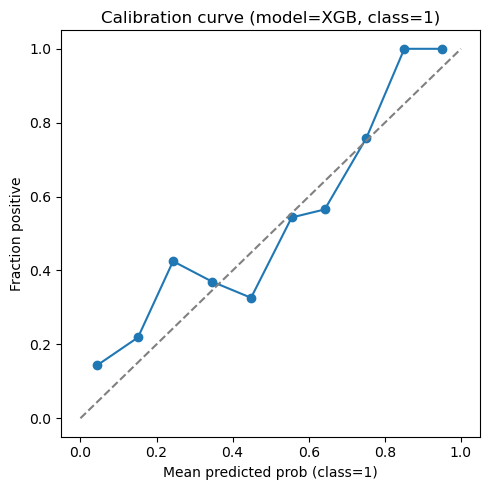

In [10]:
# Cell 8 (binary): Brier score + calibration for positive class=1
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

calib_rows = []
for m in df_folds['model'].unique():
    g = task_df[task_df['model']==m].copy()
    if g.empty:
        continue
    brier = np.mean((1.0 - g['prob_true'])**2)
    calib_rows.append({'model': m, 'brier_task': brier})
pd.DataFrame(calib_rows).to_csv(SAVE_DIR / "brier_task_by_model_binary.csv", index=False)

# calibration curve for best_model for positive class (1)
g = task_df[task_df['model']==best_model].copy()
if not g.empty:
    y_true = (g['true'] == 1).astype(int)
    # prob_true corresponds to the probability of the true class; for calibration of class=1 we must get the prob of class=1
    # If true==1 then prob_true is prob(class=1). But we need per-row prob(class=1), not only when true==1:
    # build per-row prob_class1: if info['prob'] stores [p0,p1], we need p1 for every row.
    # Rebuild: extract per-row p1 from the task JSONs instead of using prob_true
    # Let's reconstruct p1 for best_model:
    probs_p1 = []
    rows = []
    for j in folds:
        fold = int(j['test_subject'])
        m = j['models'].get(best_model, {})
        tlev = m.get('task_level_summary', {})
        for tid, info in (tlev.items() if isinstance(tlev, dict) else []):
            if info.get('prob') is not None:
                # binary: info['prob'] = [p0, p1]
                try:
                    p1 = float(info['prob'][1])
                except Exception:
                    p1 = np.nan
            else:
                p1 = np.nan
            true = info.get('true', np.nan)
            rows.append({'fold': fold, 'task_id': tid, 'true': int(true) if not np.isnan(true) else np.nan, 'p1': p1})
    p1_df = pd.DataFrame(rows).dropna(subset=['p1'])
    y_true = (p1_df['true'] == 1).astype(int)
    y_prob = p1_df['p1'].values
    if len(y_prob) > 0:
        frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=10)
        plt.figure(figsize=(5,5))
        plt.plot(mean_pred, frac_pos, marker='o')
        plt.plot([0,1],[0,1],'--', color='gray')
        plt.xlabel('Mean predicted prob (class=1)')
        plt.ylabel('Fraction positive')
        plt.title(f'Calibration curve (model={best_model}, class=1)')
        plt.tight_layout()
        plt.savefig(SAVE_DIR / f"fig5_calibration_{best_model}_binary_class1.png", dpi=200)
        plt.show()